In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor  
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.model_selection import train_test_split
from scipy.special import expit


In [2]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [3]:
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight

In [4]:
print(len(bream_length))
print(len(smelt_length))

35
14


In [ ]:
label = ['bream']*35+['smelt']*14
# label
data = [[l,w] for l, w in zip(total_length,total_weight)]
print(data)

[[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0], [29.7, 450.0], [29.7, 500.0], [30.0, 390.0], [30.0, 450.0], [30.7, 500.0], [31.0, 475.0], [31.0, 500.0], [31.5, 500.0], [32.0, 340.0], [32.0, 600.0], [32.0, 600.0], [33.0, 700.0], [33.0, 700.0], [33.5, 610.0], [33.5, 650.0], [34.0, 575.0], [34.0, 685.0], [34.5, 620.0], [35.0, 680.0], [35.0, 700.0], [35.0, 725.0], [35.0, 720.0], [36.0, 714.0], [36.0, 850.0], [37.0, 1000.0], [38.5, 920.0], [38.5, 955.0], [39.5, 925.0], [41.0, 975.0], [41.0, 950.0], [9.8, 6.7], [10.5, 7.5], [10.6, 7.0], [11.0, 9.7], [11.2, 9.8], [11.3, 8.7], [11.8, 10.0], [11.8, 9.9], [12.0, 9.8], [12.2, 12.2], [12.4, 13.4], [13.0, 12.2], [14.3, 19.7], [15.0, 19.9]]


In [9]:
train_data, test_data, train_label, test_label = train_test_split(data,label)


In [ ]:
data = np.column_stack((total_length, total_weight))
# np.ones()는 숫자 1을 원하는 개수만큼 채워주는 함수이고, np.zeros()는 숫자 0을 원하는 개수만큼 채워주는 함수
# 숫자 순서가 아니라 '내가 찾으려는 목표 대상 = 1', '나머지 대상 = 0'이라는 규칙 때문에 1이 먼저 나오고 0이 나중에 나온 것
label = np.concatenate((np.ones(35),np.zeros(14)))

In [11]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [12]:
lr = LogisticRegression()
lr.fit(train_scaled, train_label)

predict = lr.predict(test_scaled)
print('예측 생선 :', predict)

print('train 정확도 :', lr.score(train_scaled, train_label))
print('test 정확도 :', lr.score(test_scaled, test_label))

예측 생선 : ['smelt' 'bream' 'bream' 'bream' 'bream' 'smelt' 'bream' 'bream' 'bream'
 'bream' 'smelt' 'smelt' 'smelt']
train 정확도 : 1.0
test 정확도 : 1.0


In [13]:
lr.predict_proba(test_scaled)[:5]

array([[0.08337352, 0.91662648],
       [0.99322741, 0.00677259],
       [0.94513961, 0.05486039],
       [0.95248872, 0.04751128],
       [0.82308458, 0.17691542]])

In [14]:
decision = lr.decision_function(test_scaled[:5])
np.round(decision,decimals=4)
expit(decision)

array([0.91662648, 0.00677259, 0.05486039, 0.04751128, 0.17691542])

In [15]:
new = [[21,90]]
new = [[25,150]]

In [32]:
# in_data = input('생선의 길이(cm), 무게(g)를 입력하세요: 예)21,90')
in_data = '21,9'
in_data = in_data.split(',')
in_data2 = list(map(float, in_data))
in_data2

[21.0, 9.0]

In [33]:
new_scaled = ss.transform ([[21,90]])
new2_scaled = ss.transform ([[25,150]])

In [34]:
result = lr.predict(new_scaled)
result2 = lr.predict(new2_scaled)
result[0]
p_result = lr.predict_proba(new_scaled)
p_result2 = lr.predict_proba(new2_scaled)
p_result[0][0]
print(f'예측생선 : {result[0]} / ({p_result[0][1]*100:.2f} %)')
print(f'예측생선 : {result2[0]} / ({p_result2[0][0]*100:.2f} %)')

예측생선 : smelt / (55.44 %)
예측생선 : bream / (67.58 %)


In [19]:
train_scaled[:,0]

array([ 0.41444676,  0.61995754, -0.26373884, -1.7125899 ,  0.17810935,
       -1.33239494,  0.10618057, -1.40432372, -1.79479422,  0.72271294,
        0.10618057,  0.41444676,  0.61995754,  0.56857985,  0.67133524,
        0.36306906, -1.64066113,  0.72271294,  0.20893597,  0.41444676,
        0.51720215, -1.72286544,  1.3392453 ,  0.72271294, -0.15070791,
        0.72271294, -1.74341652, -1.6612122 ,  1.18511221,  0.31169136,
        0.56857985,  1.08235682,  1.3392453 ,  0.82546833,  0.28086474,
       -1.59955897])

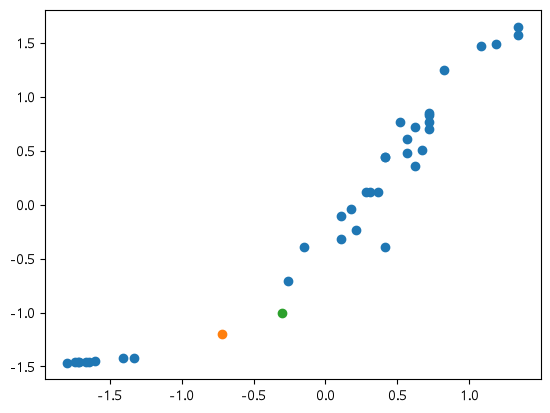

In [20]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()

In [21]:
lr.predict_proba(test_scaled[:5])

array([[0.08337352, 0.91662648],
       [0.99322741, 0.00677259],
       [0.94513961, 0.05486039],
       [0.95248872, 0.04751128],
       [0.82308458, 0.17691542]])

In [22]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)

array([0.91662648, 0.00677259, 0.05486039, 0.04751128, 0.17691542])

In [ ]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))   

train정확도 :  1.0
test정확도 :  1.0


In [24]:
in_data = input('생선의 길이(cm), 무게(g)를 입력하세요: ')
in_data = in_data.split(',')
in_data = list(map(float, in_data))

in_data_scaled = ss.transform([in_data])
proba = lr.predict_proba(in_data_scaled)

if proba[0][1] >= 0.7:
    print('예측 생선 : 도미(Bream)')
elif proba[0][0] >= 0.7:
    print('예측 생선 : 빙어(Smelt)')
else:
    print('판단하기 어려운 생선입니다.')

판단하기 어려운 생선입니다.


In [25]:
print('입력값:', in_data)
print('정규화값:', ss.transform([in_data]))
print('예측결과:', lr.predict(ss.transform([in_data])))

입력값: [21.0, 9.0]
정규화값: [[-0.71586258 -1.45924364]]
예측결과: ['smelt']
